# Tópico 1 — Contextualização, Checagem e Sanidade dos Dados
 **Base de Dados:** *Diabetes 130-US hospitals for years 1999-2008* (UCI Machine Learning Repository)

---
## Diagnóstico de Valores Faltantes, Falsos Missings e Anomalias

Nesta primeira etapa de checagem de sanidade, inspecionamos a base bruta antes de qualquer transformação para diagnosticar:
1. **Valores Faltantes Reais (`?`) vs. Falsos Missings (`"None"`):** Na base original, ausências de registro são codificadas como `?`. Entretanto, nas variáveis de exames laboratoriais (`A1Cresult` e `max_glu_serum`), o valor `"None"` indica que o exame não foi solicitado durante a internação, uma decisão clínica altamente informativa que o Pandas converteria erroneamente em `NaN` caso não utilizemos `keep_default_na=False`.
2. **Atributos com Variância Zero (Constantes):** Identificação de medicamentos ou variáveis que assumem um único valor em todas as observações.
3. **Dependência Amostral (Múltiplas Internações por Paciente):** Quantificação de leituras repetidas do mesmo `patient_nbr`.
4. **Vazamento de Dados (*Data Leakage* Clínico) e Anomalias de Cadastro:** Identificação de pacientes cujo desfecho da internação foi óbito ou transferência para cuidados paliativos terminais (*hospice*), os quais possuem probabilidade estruturalmente nula de readmissão.

In [5]:
import pandas as pd
import numpy as np

# Carregando a base bruta tratando APENAS '?' como valor ausente (NaN),
# preservando a string 'None' nas colunas de exames (A1Cresult e max_glu_serum)
df_raw = pd.read_csv(
    "data/diabetic_data.csv",
    keep_default_na=False,
    na_values=["?"],
    low_memory=False,
)

print("=" * 50)
print("1. DIMENSÕES BRUTAS E DEPENDÊNCIA AMOSTRAL")
print("=" * 50)
n_total = len(df_raw)
n_pacientes = df_raw["patient_nbr"].nunique()
print(f"• Total de registros (internações) : {n_total:,}")
print(f"• Total de atributos brutos        : {df_raw.shape[1]}")
print(f"• Total de pacientes únicos        : {n_pacientes:,}")
print(f"• Internações repetidas (mesmo ID) : {n_total - n_pacientes:,} ({(n_total - n_pacientes)/n_total:.1%})")

print("\n" + "=" * 50)
print("2. DIAGNÓSTICO DE VALORES FALTANTES REAIS")
print("=" * 50)
missing_counts = df_raw.isna().sum()
missing_df = pd.DataFrame({
    "Faltantes (?)": missing_counts[missing_counts > 0],
    "Percentual (%)": (missing_counts[missing_counts > 0] / n_total * 100).round(2)
}).sort_values(by="Percentual (%)", ascending=False)
display(missing_df)

print("\n" + "=" * 50)
print("3. VERIFICAÇÃO DE FALSOS MISSINGS")
print("=" * 50)
for col in ["A1Cresult", "max_glu_serum"]:
    print(f"\nDistribuição de '{col}':")
    vc = df_raw[col].value_counts()
    vc_pct = (df_raw[col].value_counts(normalize=True) * 100).round(2)
    display(pd.DataFrame({"Contagem": vc, "Percentual (%)": vc_pct}))

print("\n" + "=" * 75)
print("4. ATRIBUTOS CONSTANTES (VARIÂNCIA ZERO)")
print("=" * 75)
nunique_series = df_raw.nunique(dropna=False)
const_cols = nunique_series[nunique_series <= 1].index.tolist()
for c in const_cols:
    print(f"• Coluna constante detectada: '{c}' com valor único: {df_raw[c].unique().tolist()}")

print("\n" + "=" * 75)
print("5. ANOMALIAS E VAZAMENTO DE DESFECHO (DATA LEAKAGE CLÍNICO)")
print("=" * 75)
expired_ids = [11, 13, 14, 19, 20, 21] # IDs de alta correspondentes a óbito ou hospice segundo o dicionário IDS_mapping.csv
mask_expired = df_raw["discharge_disposition_id"].isin(expired_ids)
mask_invalid_gender = df_raw["gender"] == "Unknown/Invalid"

print(f"• Registros com alta por óbito/hospice (IDs {expired_ids}): {mask_expired.sum():,} ({mask_expired.mean():.2%})")
print(f"  • Taxa de readmissão nesses registros: {(df_raw.loc[mask_expired, 'readmitted'] != 'NO').mean():.2%} (vazamento determinístico)")
print(f"• Registros com gênero 'Unknown/Invalid': {mask_invalid_gender.sum()}")

1. DIMENSÕES BRUTAS E DEPENDÊNCIA AMOSTRAL
• Total de registros (internações) : 101,766
• Total de atributos brutos        : 50
• Total de pacientes únicos        : 71,518
• Internações repetidas (mesmo ID) : 30,248 (29.7%)

2. DIAGNÓSTICO DE VALORES FALTANTES REAIS


,Faltantes (?),Percentual (%)
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02



3. VERIFICAÇÃO DE FALSOS MISSINGS

Distribuição de 'A1Cresult':


,Contagem,Percentual (%)
A1Cresult,,
None,84748,83.28
>8,8216,8.07
Norm,4990,4.90
>7,3812,3.75



Distribuição de 'max_glu_serum':


,Contagem,Percentual (%)
max_glu_serum,,
None,96420,94.75
Norm,2597,2.55
>200,1485,1.46
>300,1264,1.24



4. ATRIBUTOS CONSTANTES (VARIÂNCIA ZERO)
• Coluna constante detectada: 'examide' com valor único: ['No']
• Coluna constante detectada: 'citoglipton' com valor único: ['No']

5. ANOMALIAS E VAZAMENTO DE DESFECHO (DATA LEAKAGE CLÍNICO)
• Registros com alta por óbito/hospice (IDs [11, 13, 14, 19, 20, 21]): 2,423 (2.38%)
  • Taxa de readmissão nesses registros: 3.55% (vazamento determinístico)
• Registros com gênero 'Unknown/Invalid': 3


---
## Filtragem Clínica, Agrupamento CID-9 e Tipagem Estatística

Com base no diagnóstico da etapa anterior, aplicamos as seguintes decisões formais de sanidade:
1. **Remoção de Vazamento e Anomalias:** Exclusão das internações encerradas em óbito ou cuidados paliativos terminais e dos 3 registros com `gender == 'Unknown/Invalid'`.
2. **Independência Amostral (*i.i.d.*):** Ordenação cronológica por `encounter_id` e retenção exclusiva da primeira internação de cada paciente (`patient_nbr`).
3. **Agrupamento Clínico dos Códigos CID-9 (`diag_1`, `diag_2`, `diag_3`):** As três variáveis de diagnóstico possuem mais de 700 códigos CID-9 distintos (alta cardinalidade esparsa). Seguindo a taxonomia clínica de *Strack et al. (2014)*, mapeamos cada código para 9 capítulos fisiopatológicos: `Circulatory`, `Respiratory`, `Digestive`, `Diabetes`, `Injury`, `Musculoskeletal`, `Genitourinary`, `Neoplasms` e `Other`, além de `Missing` quando ausente.
4. **Descarte de Colunas Inviáveis ou Sem Variância:** Exclusão de identificadores (`encounter_id`, `patient_nbr`), variáveis com ausência extrema ou cunho administrativo (`weight`, `payer_code`, `medical_specialty`) e medicamentos constantes (`examide`, `citoglipton`).

In [9]:
def map_icd9_to_category(code) -> str:
    """
    Mapeia códigos CID-9 (ICD-9) para os 9 grupos fisiopatológicos de Strack et al. (2014).
    """
    if pd.isna(code):
        return "Missing"
    s = str(code).strip()
    if not s or s == "?":
        return "Missing"
    # Códigos suplementares V (fatores de saúde) ou E (causas externas)
    if s.startswith(("V", "E")):
        return "Other"
    # Código que começam com 250 corresponde diretamente a Diabetes Mellitus
    if s.startswith("250"):
        return "Diabetes"
    try:
        val = float(s)
    except ValueError:
        return "Other"
    
    if (390 <= val <= 459) or val == 785:
        return "Circulatory"
    elif (460 <= val <= 519) or val == 786:
        return "Respiratory"
    elif (520 <= val <= 579) or val == 787:
        return "Digestive"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif (580 <= val <= 629) or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

# Aplicando filtros de sanidade nas linhas
df_clean = df_raw.copy()
df_clean = df_clean[~df_clean["discharge_disposition_id"].isin(expired_ids)]
df_clean = df_clean[df_clean["gender"] != "Unknown/Invalid"]
df_clean = df_clean.sort_values("encounter_id").drop_duplicates(subset=["patient_nbr"], keep="first").reset_index(drop=True)

# Definindo a variável alvo binária
df_clean["target_readmitted"] = (df_clean["readmitted"] != "NO").astype(int)
df_clean["target_early_30d"] = (df_clean["readmitted"] == "<30").astype(int)

# Agrupando diag_1, diag_2 e diag_3 nos 9 capítulos clínicos
for diag_col in ["diag_1", "diag_2", "diag_3"]:
    df_clean[diag_col] = df_clean[diag_col].apply(map_icd9_to_category)

# Mapeando faixa etária ordinal para ponto médio numérico
age_map = {f"[{i}-{i+10})": i + 5 for i in range(0, 100, 10)}
df_clean["age_years"] = df_clean["age"].map(age_map)

# Convertendo IDs administrativos numéricos em categorias nominais
for id_col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df_clean[id_col] = "ID_" + df_clean[id_col].astype(str)

# Removendo colunas descartadas
cols_to_drop = [
    "encounter_id", "patient_nbr", "readmitted", "age",
    "weight", "payer_code", "medical_specialty",
    "examide", "citoglipton"
]
X_sanitized = df_clean.drop(columns=cols_to_drop + ["target_readmitted", "target_early_30d"])
y_sanitized = df_clean["target_readmitted"]

print("=" * 80)
print("RESUMO PÓS-SANIDADE DA COORTE DE PACIENTES ÚNICOS")
print("=" * 80)
print(f"• Pacientes únicos elegíveis          : {len(X_sanitized):,}")
print(f"• Atributos preditivos antes do One-Hot   : {X_sanitized.shape[1]}")
print(f"• Taxa de Readmissão Global (<30 ou >30)  : {y_sanitized.mean():.2%} ({y_sanitized.sum():,} positivos vs. {(1-y_sanitized).sum():,} negativos)")
print(f"• Taxa de Readmissão Precoce (<30 dias)   : {df_clean['target_early_30d'].mean():.2%}")

for diag_col, titulo in [
    ("diag_1", "DIAGNÓSTICO diag_1"),
    ("diag_2", "DIAGNÓSTICO diag_2"),
    ("diag_3", "DIAGNÓSTICO diag_3"),
]:
    print("\n" + "=" * 80)
    print(f"DISTRIBUIÇÃO DOS GRUPOS CLÍNICOS CID-9 ({titulo})")
    print("=" * 80)
    diag_summary = pd.DataFrame({
        "Pacientes": X_sanitized[diag_col].value_counts(),
        "Proporção (%)": (X_sanitized[diag_col].value_counts(normalize=True) * 100).round(2),
        "Taxa Readmissão (%)": (df_clean.groupby(diag_col)["target_readmitted"].mean() * 100).round(2)
    }).sort_values(by="Pacientes", ascending=False)
    display(diag_summary)

print("\n" + "=" * 50)
print("TABELA DE TIPAGEM ESTATÍSTICA DOS ATRIBUTOS")
print("=" * 50)
num_cols = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]
ord_cols = ["age_years"]
cat_cols = [c for c in X_sanitized.columns if c not in num_cols + ord_cols]

typing_summary = pd.DataFrame([
    {
        "Grupo Estatístico": "Numéricas Discretas / Contagem",
        "Qtd. Atributos": len(num_cols),
        "Variáveis": ", ".join(num_cols),
        "Tratamento no Pipeline (Seção 3)": "Imputação por Mediana + StandardScaler"
    },
    {
        "Grupo Estatístico": "Ordinal Mapeada",
        "Qtd. Atributos": len(ord_cols),
        "Variáveis": "age_years (ponto médio: 5 a 95 anos)",
        "Tratamento no Pipeline (Seção 3)": "StandardScaler"
    },
    {
        "Grupo Estatístico": "Categóricas Nominais e Exames",
        "Qtd. Atributos": 10,
        "Variáveis": "race, gender, admission_type_id, discharge_disposition_id, admission_source_id, diag_1, diag_2, diag_3, max_glu_serum, A1Cresult",
        "Tratamento no Pipeline (Seção 3)": "Imputação 'Missing' + OneHotEncoder(handle_unknown='ignore')"
    },
    {
        "Grupo Estatístico": "Medicações e Mudança Terapêutica",
        "Qtd. Atributos": len(cat_cols) - 10,
        "Variáveis": "metformin, insulin, change, diabetesMed + 19 fármacos hipoglicemiantes",
        "Tratamento no Pipeline (Seção 3)": "OneHotEncoder(drop='if_binary')"
    }
])
display(typing_summary)

RESUMO PÓS-SANIDADE DA COORTE DE PACIENTES ÚNICOS
• Pacientes únicos elegíveis          : 69,987
• Atributos preditivos antes do One-Hot   : 42
• Taxa de Readmissão Global (<30 ou >30)  : 40.74% (28,511 positivos vs. 41,476 negativos)
• Taxa de Readmissão Precoce (<30 dias)   : 8.98%

DISTRIBUIÇÃO DOS GRUPOS CLÍNICOS CID-9 (DIAGNÓSTICO diag_1)


,Pacientes,Proporção (%),Taxa Readmissão (%)
diag_1,,,
Circulatory,21389,30.56,42.55
Other,12124,17.32,40.08
Respiratory,9491,13.56,42.79
Digestive,6488,9.27,39.60
Diabetes,5748,8.21,42.83
Injury,4694,6.71,39.26
Musculoskeletal,4064,5.81,35.58
Genitourinary,3441,4.92,38.83
Neoplasms,2538,3.63,32.70



DISTRIBUIÇÃO DOS GRUPOS CLÍNICOS CID-9 (DIAGNÓSTICO diag_2)


,Pacientes,Proporção (%),Taxa Readmissão (%)
diag_2,,,
Circulatory,22083,31.55,42.98
Other,18080,25.83,40.07
Diabetes,9700,13.86,37.96
Respiratory,6928,9.90,42.48
Genitourinary,5330,7.62,41.20
Digestive,2856,4.08,37.96
Injury,1822,2.60,35.35
Neoplasms,1600,2.29,42.31
Musculoskeletal,1295,1.85,37.61



DISTRIBUIÇÃO DOS GRUPOS CLÍNICOS CID-9 (DIAGNÓSTICO diag_3)


,Pacientes,Proporção (%),Taxa Readmissão (%)
diag_3,,,
Circulatory,20866,29.81,42.53
Other,20026,28.61,39.79
Diabetes,12547,17.93,38.69
Respiratory,4652,6.65,44.63
Genitourinary,4049,5.79,43.81
Digestive,2700,3.86,41.85
Injury,1409,2.01,36.62
Musculoskeletal,1368,1.95,38.89
Missing,1224,1.75,26.06



TABELA DE TIPAGEM ESTATÍSTICA DOS ATRIBUTOS


,Grupo Estatístico,Qtd. Atributos,Variáveis,Tratamento no Pipeline (Seção 3)
0,Numéricas Discretas / Contagem,8,"time_in_hospital, num_lab_procedures, num_proc...",Imputação por Mediana + StandardScaler
1,Ordinal Mapeada,1,age_years (ponto médio: 5 a 95 anos),StandardScaler
2,Categóricas Nominais e Exames,10,"race, gender, admission_type_id, discharge_dis...",Imputação 'Missing' + OneHotEncoder(handle_unk...
3,Medicações e Mudança Terapêutica,23,"metformin, insulin, change, diabetesMed + 19 f...",OneHotEncoder(drop='if_binary')


---
## Propriedades Distributivas que Condicionam os Modelos

Foi gerada uma figura composta de 3 painéis para o Relatório Técnico:
- **Painel (a) — Distribuição Marginal da Variável Alvo ($\mathbf{y}$):** Demonstra a proporção de classes ($59{,}26\%$ Não Readmitido vs. $40{,}74\%$ Readmitido), evidenciando o baseline majoritário ($59{,}26\%$ de acurácia ingênua).
- **Painel (b) — Assimetria Extrema (*Right-Skewness*) e Relação Monotônica Não-Linear:** Mostra a distribuição de `number_inpatient` (internações prévias) e a evolução da taxa de readmissão. Em preditores lineares ($\boldsymbol{\beta}^T \mathbf{x}$), contagens com cauda pesada dominam o produto interno na ausência de transformações ou partições por limiar, enquanto árvores (CART) são invariantes a transformações monotônicas.
- **Painel (c) — Evidência Empírica de Interação Clínica (`A1Cresult` $\times$ `change`):** Demonstra que o efeito do ajuste terapêutico (`change == 'Ch'`) sobre a readmissão varia conforme o status glicêmico (`A1Cresult`), violando a hipótese de aditividade pura de modelos lineares sem termos de interação explícitos.

ESTATÍSTICAS DESCRITIVAS E ASSIMETRIA (ATRIBUTOS NUMÉRICOS E ORDINAIS)


,Média,Desvio Padrão,Mediana,Máximo,Assimetria (Skewness)
number_emergency,0.10,0.51,0.0,42,21.23
number_outpatient,0.28,1.06,0.0,42,9.70
number_inpatient,0.18,0.60,0.0,12,5.59
num_medications,15.67,8.29,14.0,81,1.43
num_procedures,1.43,1.76,1.0,6,1.23
time_in_hospital,4.27,2.93,3.0,14,1.18
num_lab_procedures,42.88,19.89,44.0,132,-0.22
age_years,65.44,15.97,65.0,95,-0.63
number_diagnoses,7.22,2.00,8.0,16,-0.72


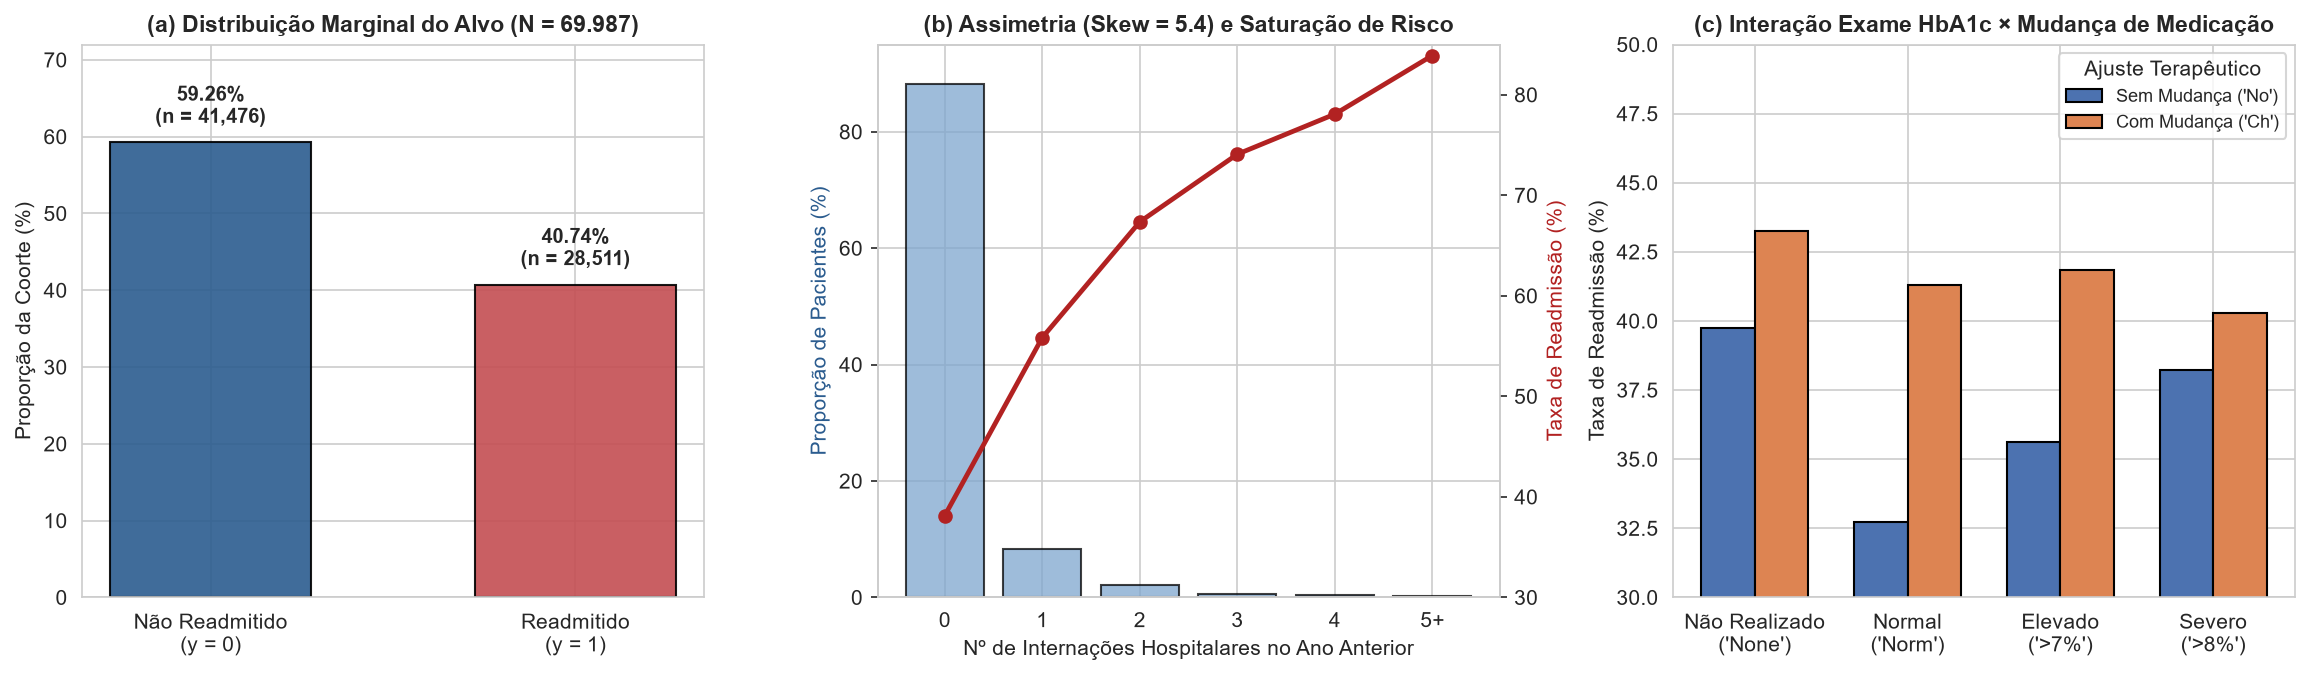

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.dpi": 150
})
sns.set_style("whitegrid")

fig_dir = Path("outputs/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Estatísticas de Assimetria e Curtose dos atributos numéricos
stats_num = pd.DataFrame({
    "Média": X_sanitized[num_cols + ord_cols].mean().round(2),
    "Desvio Padrão": X_sanitized[num_cols + ord_cols].std().round(2),
    "Mediana": X_sanitized[num_cols + ord_cols].median().round(2),
    "Máximo": X_sanitized[num_cols + ord_cols].max(),
    "Assimetria (Skewness)": X_sanitized[num_cols + ord_cols].skew().round(2)
}).sort_values(by="Assimetria (Skewness)", ascending=False)

print("=" * 80)
print("ESTATÍSTICAS DESCRITIVAS E ASSIMETRIA (ATRIBUTOS NUMÉRICOS E ORDINAIS)")
print("=" * 80)
display(stats_num)

# Criando Figura Tripla (Painéis A, B e C)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))

# PAINEL A
ax0 = axes[0]
class_counts = y_sanitized.value_counts().sort_index()
class_pcts = (class_counts / len(y_sanitized) * 100)
bars = ax0.bar(
    ["Não Readmitido\n(y = 0)", "Readmitido\n(y = 1)"],
    class_pcts.values,
    color=["#2b5c8f", "#c44e52"],
    width=0.55,
    edgecolor="black",
    alpha=0.9
)
for bar, count, pct in zip(bars, class_counts.values, class_pcts.values):
    ax0.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.8,
        f"{pct:.2f}%\n(n = {count:,})",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )
ax0.set_ylim(0, 72)
ax0.set_ylabel("Proporção da Coorte (%)")
ax0.set_title("(a) Distribuição Marginal do Alvo (N = 69.987)", fontweight="bold")

# PAINEL B 
ax1 = axes[1]
df_clean["inpatient_capped"] = df_clean["number_inpatient"].clip(upper=5)
inpatient_grp = df_clean.groupby("inpatient_capped").agg(
    n_patients=("target_readmitted", "count"),
    readm_rate=("target_readmitted", "mean")
)
labels_inp = ["0", "1", "2", "3", "4", "5+"]
pct_patients = inpatient_grp["n_patients"] / len(df_clean) * 100

ax1.bar(labels_inp, pct_patients, color="#7ea6ce", edgecolor="black", alpha=0.75, label="% de Pacientes (Eixo Esq.)")
ax1.set_xlabel("Nº de Internações Hospitalares no Ano Anterior")
ax1.set_ylabel("Proporção de Pacientes (%)", color="#2b5c8f")
ax1.set_ylim(0, 95)

ax1_twin = ax1.twinx()
ax1_twin.plot(
    labels_inp,
    inpatient_grp["readm_rate"] * 100,
    color="#b22222", marker="o", linewidth=2.3, markersize=6,
    label="Taxa de Readmissão % (Eixo Dir.)"
)
ax1_twin.set_ylabel("Taxa de Readmissão (%)", color="#b22222")
ax1_twin.set_ylim(30, 85)
ax1_twin.grid(False)
ax1.set_title("(b) Assimetria (Skew = 5.4) e Saturação de Risco", fontweight="bold")

# PAINEL C
ax2 = axes[2]
order_a1c = ["None", "Norm", ">7", ">8"]
inter_df = (
    df_clean.groupby(["A1Cresult", "change"])["target_readmitted"]
    .mean()
    .unstack()
    .loc[order_a1c] * 100
)
x_idx = np.arange(len(order_a1c))
w = 0.35
ax2.bar(x_idx - w/2, inter_df["No"], width=w, label="Sem Mudança ('No')", color="#4c72b0", edgecolor="black")
ax2.bar(x_idx + w/2, inter_df["Ch"], width=w, label="Com Mudança ('Ch')", color="#dd8452", edgecolor="black")
ax2.set_xticks(x_idx)
ax2.set_xticklabels(["Não Realizado\n('None')", "Normal\n('Norm')", "Elevado\n('>7%')", "Severo\n('>8%')"])
ax2.set_ylabel("Taxa de Readmissão (%)")
ax2.set_ylim(30, 50)
ax2.legend(title="Ajuste Terapêutico", frameon=True, fontsize=8.5)
ax2.set_title("(c) Interação Exame HbA1c × Mudança de Medicação", fontweight="bold")

plt.tight_layout()
out_fig_path = fig_dir / "fig1_sanidade_dados.png"
plt.savefig(out_fig_path, dpi=300, bbox_inches="tight")
plt.show()